# LDA Comparison

**Cross-notebook comparison of `lda_v1`–`lda_v4`.**

*All four LDA notebooks must be run end-to-end before this notebook, so that the JSON artifacts exist.*

## 1. Methodology recap

Four flat-LDA configurations are compared in a 2×2 design: **inference algorithm** (gensim VB vs tomotopy CGS) × **document granularity** (page vs deck). Each notebook reports up to three K values:

- **INITIAL** — the domain-motivated starting K (K=10 for page-level, K=5 for deck-level).
- **OWN_BEST** — a grid-informed K selected per notebook (`lda_v1` K=4, `lda_v2` K=11, `lda_v3` K=3, `lda_v4` K=3). For the deck-level notebooks this is the grid maximum; for the page-level notebooks it is a parsimonious choice (gensim's unconstrained maximum is K=3; tomotopy's C_v rises monotonically to K=20, so K=11 is chosen for parsimony).
- **CROSS_BEST** — the OWN_BEST of the paired library at the same granularity, trained here for a direct library comparison at equivalent K (`lda_v1` at K=11, `lda_v2` at K=4). **Only available for the two page-level notebooks.**

**Train/test split:** all four notebooks use a deterministic holdout split (`random_state=42`). Page-level (`lda_v1`, `lda_v2`): 108 train / 13 test pages; deck-level (`lda_v3`, `lda_v4`): leave-one-out (8 train / 1 test). All four train on their training partition only and report holdout perplexity (gensim via `compute_holdout_perplexity_gensim`, tomotopy via `compute_holdout_perplexity`).

Metrics:
- **C_v coherence** (higher is better; computed with each library's native estimator, so absolute values are not directly comparable across libraries — see the common-estimator cross-library check in the discussion);
- **U_mass coherence** (higher / closer to 0 is better; not strictly comparable across libraries);
- **in-sample raw perplexity** (lower is better; gensim's `log_perplexity` is converted via `exp(-log_pp)` so both libraries report on the same scale);
- **holdout raw perplexity** (lower is better; out-of-sample on the held-out pages/deck — tomotopy via `model.infer()`, gensim via inferred θ scored as P(w|θ,φ); not comparable in absolute value to in-sample perplexity or across the two estimators, but valid within the same estimator);
- **topic diversity (Dieng et al. 2020)** (unique words across top-25 / K×25; higher is better);
- **mean pairwise cosine similarity** of topic–word distributions (lower = more distinct topics);
- **mean Shannon entropy** of document–topic distributions (higher = more spread-out; max is log(K) so `entropy_norm` ∈ [0,1] enables cross-K comparison).

In [1]:
import os, sys, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_nb_dir = os.path.dirname(os.path.abspath('lda_comparison.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)
from utils import OUTPUT_ROOT

plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 12,
    'axes.labelsize'   : 10,
    'font.family'      : 'serif',
})

paths = sorted(glob.glob(os.path.join(OUTPUT_ROOT, 'lda_v*_metrics.json')))
assert len(paths) == 4, f'Expected 4 metrics JSON files, found {len(paths)}: {paths}'

rows = []
raw = {}
for p in paths:
    with open(p) as f:
        d = json.load(f)
    raw[d['notebook']] = d
    role_map = {cfg['role']: cfg for cfg in d['configs']}
    for role in ('initial', 'own_library_best', 'cross_library_best'):
        if role not in role_map:
            continue
        m = role_map[role]
        rows.append({
            'notebook'              : d['notebook'],
            'library'               : d['library'],
            'granularity'           : d['granularity'],
            'role'                  : role,
            'K'                     : m['k'],
            'C_v'                   : m['coherence_c_v'],
            'U_mass'                : m['coherence_u_mass'],
            'raw_perplexity'        : m['raw_perplexity'],
            'log_perplexity'        : m['log_perplexity'],
            'holdout_raw_perplexity': m.get('holdout_raw_perplexity'),   # tomotopy only
            'topic_diversity'       : m['topic_diversity_top25']['diversity'],
            'cosine_sim_mean'       : m['cosine_similarity_mean'],
            'cosine_sim_max'        : m['cosine_similarity_max'],
            'entropy_mean'          : m['shannon_entropy_mean'],
            'entropy_mean_norm'     : m['shannon_entropy_mean_norm'],
        })

CV_THRESHOLD = 0.50

summary_df = pd.DataFrame(rows).sort_values(
    ['notebook'],
    ascending=[True],
).reset_index(drop=True)

def _highlight_cv(val):
    if not isinstance(val, float):
        return ''
    if val >= CV_THRESHOLD:
        return 'background-color: #e8f5e9; color: #1b5e20; font-weight: bold'
    else:
        return 'background-color: #ffebee; color: #b71c1c; font-weight: bold'

# higher-is-better metrics get best=green/worst=red; lower-is-better are inverted.
_HIGHER_IS_BETTER = {
    'C_v': True, 'U_mass': True,
    'raw_perplexity': False, 'log_perplexity': True,
    'holdout_raw_perplexity': False,
    'topic_diversity': True,
    'cosine_sim_mean': False, 'cosine_sim_max': False,
    'entropy_mean': True, 'entropy_mean_norm': True,
}

def _highlight_best_worst(s):
    styles = [''] * len(s)
    vals = pd.to_numeric(s, errors='coerce')
    if vals.isna().all():
        return styles
    higher_is_better = _HIGHER_IS_BETTER.get(s.name, True)
    best_idx  = vals.idxmax() if higher_is_better else vals.idxmin()
    worst_idx = vals.idxmin() if higher_is_better else vals.idxmax()
    # C_v already gets its own colouring via _highlight_cv; skip best/worst there.
    if s.name == 'C_v':
        return styles
    pos = s.index.get_loc
    styles[pos(best_idx)]  = 'background-color: #e8f5e9; color: #1b5e20; font-weight: bold'
    styles[pos(worst_idx)] = 'background-color: #ffebee; color: #b71c1c; font-weight: bold'
    return styles

def _fmt_holdout(v):
    return '—' if (v is None or (isinstance(v, float) and np.isnan(v))) else f'{v:.2f}'

summary_df.style.format({
    'C_v': '{:.4f}', 'U_mass': '{:.4f}',
    'raw_perplexity': '{:.2f}', 'log_perplexity': '{:.4f}',
    'holdout_raw_perplexity': _fmt_holdout,
    'topic_diversity': '{:.4f}',
    'cosine_sim_mean': '{:.4f}', 'cosine_sim_max': '{:.4f}',
    'entropy_mean': '{:.4f}', 'entropy_mean_norm': '{:.4f}',
}).map(_highlight_cv, subset=['C_v']).apply(
    _highlight_best_worst,
    subset=['U_mass', 'raw_perplexity', 'log_perplexity',
            'holdout_raw_perplexity',
            'topic_diversity', 'cosine_sim_mean', 'cosine_sim_max',
            'entropy_mean', 'entropy_mean_norm'],
).set_caption(
    f'All four notebooks X {{initial, own_library_best, cross_library_best}} — full metric panel'
    f'  (C_v ≥ {CV_THRESHOLD} = green, < {CV_THRESHOLD} = red; per-metric best = green, worst = red)'
    f'  (holdout perplexity: tomotopy models only; — = not available)'
)

,notebook,library,granularity,role,K,C_v,U_mass,raw_perplexity,log_perplexity,holdout_raw_perplexity,topic_diversity,cosine_sim_mean,cosine_sim_max,entropy_mean,entropy_mean_norm
0,lda_v1,gensim,page,initial,10,0.3843,-12.6753,1008.26,-6.9160,147.21,0.7120,0.1970,0.4202,4.3928,0.7418
1,lda_v1,gensim,page,own_library_best,4,0.3683,-11.5550,925.24,-6.8301,199.66,0.7600,0.3073,0.3895,4.9075,0.8287
2,lda_v1,gensim,page,cross_library_best,11,0.3809,-12.4078,1096.44,-6.9998,135.97,0.6764,0.2116,0.5255,4.3597,0.7362
3,lda_v2,tomotopy,page,initial,10,0.7896,-8.2006,451.58,-6.1128,48.61,0.9320,0.0240,0.1292,3.6453,0.6156
4,lda_v2,tomotopy,page,own_library_best,11,0.8070,-7.8211,429.20,-6.0619,48.37,0.9200,0.0296,0.3261,3.5858,0.6055
5,lda_v2,tomotopy,page,cross_library_best,4,0.7256,-10.3275,521.10,-6.2559,49.39,0.9800,0.0211,0.0318,4.3467,0.7340
6,lda_v3,gensim,deck,initial,5,0.3747,-0.6042,619.88,-6.4295,243.28,0.8160,0.2235,0.3282,4.5509,0.7898
7,lda_v3,gensim,deck,own_library_best,3,0.4221,-0.8636,560.03,-6.3280,250.69,0.8267,0.2827,0.3237,4.8410,0.8402
8,lda_v4,tomotopy,deck,initial,5,0.6165,-0.4645,423.33,-6.0482,62.73,0.9840,0.0171,0.0423,3.9428,0.6828
9,lda_v4,tomotopy,deck,own_library_best,3,0.6534,-0.4498,417.16,-6.0335,56.90,1.0000,0.0120,0.0145,4.3500,0.7533


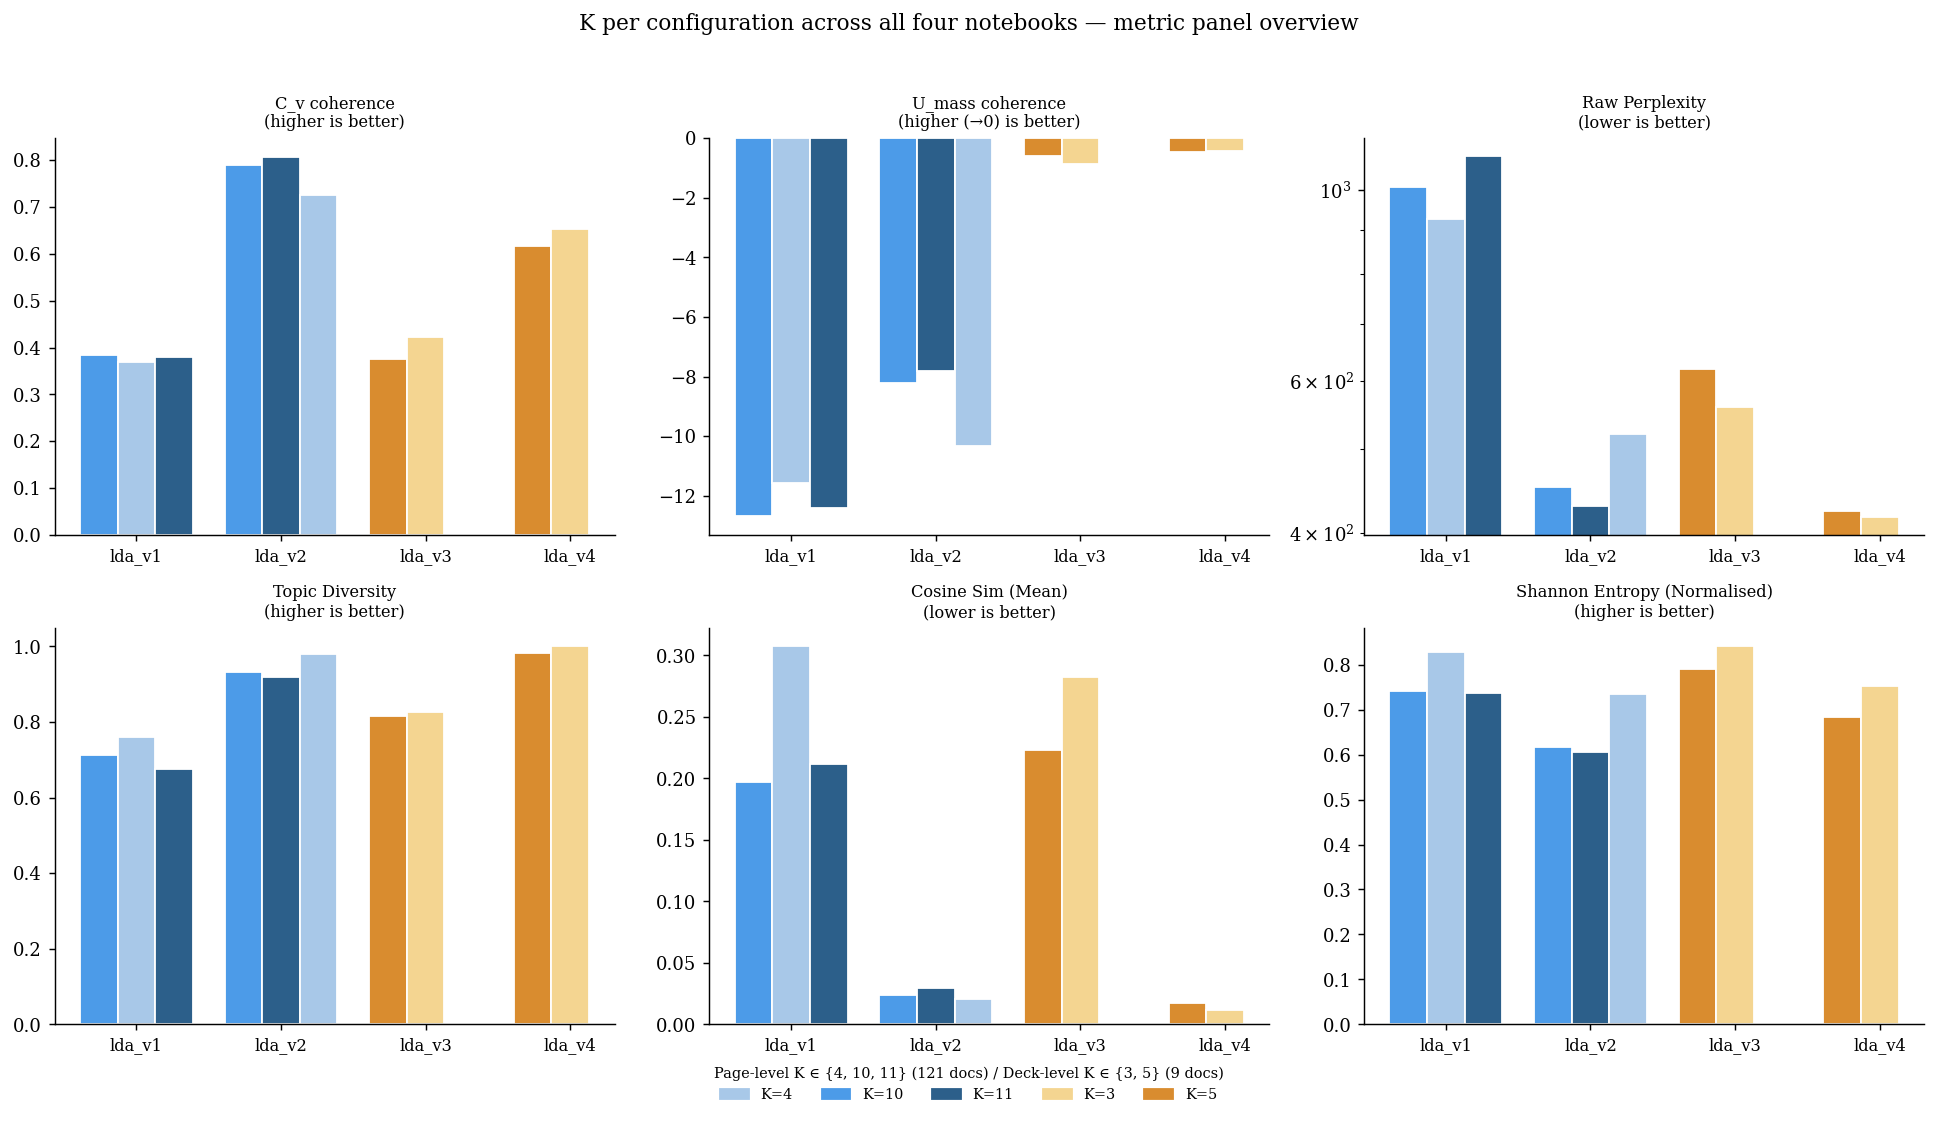

In [2]:
import matplotlib.patches as mpatches

# 2×3 grid of grouped bar charts: one panel per metric, X = notebook, hue = K value.
metrics_to_plot = [
    ('C_v',              'C_v coherence',          'higher is better', False),
    ('U_mass',           'U_mass coherence',        'higher (→0) is better', False),
    ('raw_perplexity',   'Raw Perplexity',          'lower is better',  True),
    ('topic_diversity',  'Topic Diversity',         'higher is better', False),
    ('cosine_sim_mean',  'Cosine Sim (Mean)',       'lower is better',  False),
    ('entropy_mean_norm','Shannon Entropy (Normalised)',    'higher is better', False),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
notebooks = sorted(summary_df['notebook'].unique())
x = np.arange(len(notebooks))
width = 0.26
roles = ['initial', 'own_library_best', 'cross_library_best']

# Blue shades for page-level K values (121 docs); orange shades for deck-level (9 docs).
k_colors = {
    4:  '#A8C8E8',
    10: '#4C9BE8',
    11: '#2C5F8A',
    3:  '#F4D591',
    5:  '#D98C2F',
}

for ax, (metric, title, direction, log_y) in zip(axes, metrics_to_plot):
    for i, role in enumerate(roles):
        offset = (i - 1) * width
        for j, nb in enumerate(notebooks):
            sub = summary_df[(summary_df['notebook'] == nb) & (summary_df['role'] == role)]
            if len(sub) == 0:
                continue
            k_val = int(sub['K'].iloc[0])
            val = sub[metric].iloc[0]
            ax.bar(j + offset, val, width, color=k_colors[k_val], edgecolor='white')

    ax.set_xticks(x)
    ax.set_xticklabels(notebooks, rotation=0, fontsize=9)
    ax.set_title(f'{title}\n({direction})', fontsize=9)
    if log_y:
        ax.set_yscale('log')

legend_handles = [
    mpatches.Patch(color=k_colors[k], label=f'K={k}')
    for k in [4, 10, 11, 3, 5]
]
fig.legend(
    handles=legend_handles, loc='lower center', ncol=5, fontsize=8,
    frameon=False, bbox_to_anchor=(0.5, -0.04),
    title='Page-level K ∈ {4, 10, 11} (121 docs) / Deck-level K ∈ {3, 5} (9 docs)',
    title_fontsize=8,
)

fig.suptitle(
    'K per configuration across all four notebooks — metric panel overview'
,
    y=1.02,
)
plt.tight_layout()
plt.show()


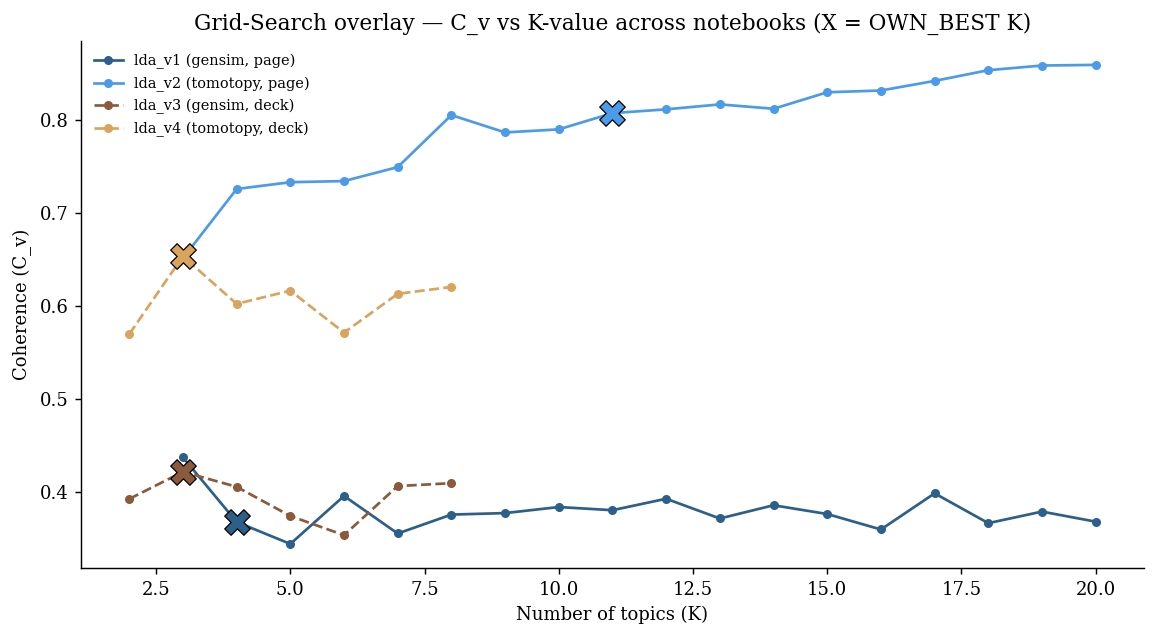

In [3]:
# overlay all four C_v-vs-K curves; star-marker the OWN_BEST K per curve.
fig, ax = plt.subplots(figsize=(9, 5))
color_map = {'lda_v1': '#2C5F8A', 'lda_v2': '#4C9BE8', 'lda_v3': '#8B5A3C', 'lda_v4': '#D9A55E'}

for nb_id, payload in raw.items():
    df = pd.DataFrame(payload['grid_search'])
    style = '--' if payload['granularity'] == 'deck' else '-'
    label = f"{nb_id} ({payload['library']}, {payload['granularity']})"
    ax.plot(df['k'], df['coherence_cv'], linestyle=style, marker='o',
            color=color_map[nb_id], markersize=4, linewidth=1.5, label=label)
    # mark the own-library-best K (role-based lookup).
    role_map = {cfg['role']: cfg for cfg in payload['configs']}
    best_cfg = role_map['own_library_best']
    ax.scatter([best_cfg['k']], [best_cfg['coherence_c_v']], marker='X', s=200,
               color=color_map[nb_id], edgecolor='black', linewidth=0.7, zorder=5)

ax.set_xlabel('Number of topics (K)')
ax.set_ylabel('Coherence (C_v)')
ax.set_title('Grid-Search overlay — C_v vs K-value across notebooks (X = OWN_BEST K)')
ax.legend(loc='best', fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


In [4]:
# pick the best baseline using a lexicographic preference on OWN_BEST rows:
# 1) highest C_v  2) lower raw_perplexity  3) higher topic_diversity
own_best = summary_df[summary_df['role'] == 'own_library_best'].copy()
own_best = own_best.sort_values(
    by=['C_v', 'raw_perplexity', 'topic_diversity'],
    ascending=[False, True, False],
).reset_index(drop=True)

best = own_best.iloc[0]
holdout_str = _fmt_holdout(best['holdout_raw_perplexity'])
print('Recommended baseline (lexicographic by C_v → raw_pp → diversity):')
print(f"  notebook       : {best['notebook']}")
print(f"  library        : {best['library']}")
print(f"  K (own_best)   : {best['K']}")
print(f"  C_v            : {best['C_v']:.4f}")
print(f"  U_mass         : {best['U_mass']:.4f}")
print(f"  raw_pp         : {best['raw_perplexity']:.2f}")
print(f"  holdout_pp     : {holdout_str}")
print(f"  diversity      : {best['topic_diversity']:.4f}")
print(f"  cosine_mean    : {best['cosine_sim_mean']:.4f}")
print(f"  entropy_norm   : {best['entropy_mean_norm']:.4f}")

# Compare lda_v2 INITIAL (K=10) vs OWN_BEST (K=11) explicitly.
v2_init = summary_df[(summary_df['notebook'] == 'lda_v2') & (summary_df['role'] == 'initial')].iloc[0]
v2_best = summary_df[(summary_df['notebook'] == 'lda_v2') & (summary_df['role'] == 'own_library_best')].iloc[0]
print()
print('Primary-baseline comparison (lda_v2):')
print(f"  K=10 (INITIAL)  C_v={v2_init['C_v']:.4f}  raw_pp={v2_init['raw_perplexity']:.2f}"
      f"  holdout_pp={_fmt_holdout(v2_init['holdout_raw_perplexity'])}"
      f"  div={v2_init['topic_diversity']:.4f}  cosine={v2_init['cosine_sim_mean']:.4f}"
      f"  ent_norm={v2_init['entropy_mean_norm']:.4f}")
print(f"  K=11 (OWN_BEST) C_v={v2_best['C_v']:.4f}  raw_pp={v2_best['raw_perplexity']:.2f}"
      f"  holdout_pp={_fmt_holdout(v2_best['holdout_raw_perplexity'])}"
      f"  div={v2_best['topic_diversity']:.4f}  cosine={v2_best['cosine_sim_mean']:.4f}"
      f"  ent_norm={v2_best['entropy_mean_norm']:.4f}")
if v2_best['C_v'] > v2_init['C_v']:
    print('  → K=11 improves C_v; recommend updating the primary baseline to lda_v2 @ K=11.')
else:
    print('  → K=10 still wins on C_v; keep the primary baseline at lda_v2 @ K=10.')

Recommended baseline (lexicographic by C_v → raw_pp → diversity):
  notebook       : lda_v2
  library        : tomotopy
  K (own_best)   : 11
  C_v            : 0.8070
  U_mass         : -7.8211
  raw_pp         : 429.20
  holdout_pp     : 48.37
  diversity      : 0.9200
  cosine_mean    : 0.0296
  entropy_norm   : 0.6055

Primary-baseline comparison (lda_v2):
  K=10 (INITIAL)  C_v=0.7896  raw_pp=451.58  holdout_pp=48.61  div=0.9320  cosine=0.0240  ent_norm=0.6156
  K=11 (OWN_BEST) C_v=0.8070  raw_pp=429.20  holdout_pp=48.37  div=0.9200  cosine=0.0296  ent_norm=0.6055
  → K=11 improves C_v; recommend updating the primary baseline to lda_v2 @ K=11.


## 3. Recommendation

The cell above mechanically selects the best OWN_BEST configuration by lexicographic ordering on (C_v ↓, raw perplexity ↑, topic diversity ↓). For the thesis, the primary flat-LDA baseline used in the hLDA comparison should be the row identified as **Recommended baseline** above (lda_v2).

The previous primary baseline (`lda_v2` @ K=10, C_v=0.7896) is explicitly compared against the selected OWN_BEST (K=11) so that any K-update is defensible: if K=11 improves C_v, the baseline shifts; otherwise it stays at K=10.

The **cross-library check** (`lda_v1` at K=11, `lda_v2` at K=4) rules out K as the sole confound between gensim and tomotopy. Note, however, that the per-library C_v values use different native estimators and are not directly comparable; a common-estimator (gensim `CoherenceModel`) re-measurement confirms CGS > VB (page-level: ≈0.52/0.47 vs ≈0.40/0.34), with a smaller margin than the native numbers suggest.

## 4. Trade-offs

- **Small corpus.** N=108 training pages (tomotopy) / N=121 pages (gensim) are below the typical sweet spot for LDA. Treat absolute metric values with caution; rely on relative ordering between models.
- **Train/test split.** All four notebooks train on their training partition only: page-level (`lda_v1`, `lda_v2`) on 108 of 121 pages, deck-level (`lda_v3`, `lda_v4`) on 8 of 9 decks (leave-one-out). All four report holdout perplexity, so page-level cross-library C_v comparisons are on equal footing (both 108 training documents).
- **Perplexity scales.** In-sample perplexity (`model.perplexity`, CGS leave-one-out) and holdout perplexity (`compute_holdout_perplexity`, conditional on sampled topic assignments) use different estimators and are **not comparable in absolute value** (scale ~430–530 vs ~43–63 respectively). Both are valid for cross-model comparison **within the same estimator**.
- **U_mass cross-library comparability.** `gensim` and `tomotopy` differ in how they handle log-zeros in U_mass; values are comparable **within** a library but not across. Use ΔU_mass within each notebook, not U_mass deltas across notebooks.
- **Perplexity unification (in-sample).** `unify_perplexity` rewrites gensim's `log_perplexity` (mean log per-word probability per document, negative) as raw perplexity = `exp(-log_pp)` so both libraries report on the same lower-is-better scale. The reported `log_perplexity` for tomotopy is derived as `-log(raw)` and follows the same sign convention.
- **Cosine similarity.** Computed over the top-10 word probability vectors per topic, averaged over all unique pairs. Lower values indicate more distinct topics.
- **Shannon entropy normalisation.** `entropy_norm = entropy / log(K)`; this maps [0, log(K)] → [0, 1] so values are comparable across different K settings.
- **Topic diversity.** N=25 with the helper's auto-clamp; for all configurations in this notebook K×N never exceeds the vocabulary, so no clamping was triggered.
- **Deck-level results are exploratory** and should not be cited as load-bearing evidence for the thesis claim. The hLDA comparison is page-level.

## 5. Topic-distribution heatmap across documents

Visualises how each topic is distributed across all documents for each of the four LDA configurations. This requires re-training each model (using the same fixed seeds and the primary K per notebook) so that per-document topic distributions are available.

**Note:** models in this section are trained on the **full corpus** (121 pages / 9 decks) for visualisation purposes — to show topic presence across every document. Evaluation metrics (C_v, perplexity, etc.) are sourced exclusively from the JSON artifacts produced by each individual notebook, where `lda_v2` uses the 90/10 holdout split.

**Page-level models (lda_v1, lda_v2):** one column per slide page (121 docs), grouped by lecture deck. Stacked area chart — each colour is one topic; height = that topic's probability in the page's distribution.

**Deck-level models (lda_v3, lda_v4):** one bar per lecture deck (9 docs). Stacked bar chart.

In [5]:

import warnings
import gensim
import tomotopy as tp
from gensim import corpora
from gensim.models import LdaModel

from utils import (
    load_corpus, tokenize_corpus,
    build_slide_page_docs, build_slide_deck_docs,
    generate_topic_labels_llm,
)

warnings.filterwarnings('ignore')

RANDOM_SEED = 42
MIN_TOKENS  = 10

# ── corpus ────────────────────────────────────────────────────────────────────
corpus_raw  = tokenize_corpus(load_corpus())

page_docs   = build_slide_page_docs(corpus_raw)
page_docs   = page_docs[page_docs['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)

deck_docs   = build_slide_deck_docs(corpus_raw)

page_texts  = page_docs['tokens'].tolist()
deck_texts  = deck_docs['tokens'].tolist()

# ── gensim helpers ────────────────────────────────────────────────────────────
def _gensim_bow(texts, min_no=2):
    d = corpora.Dictionary(texts)
    d.filter_extremes(no_below=min_no, no_above=1.0)
    return d, [d.doc2bow(t) for t in texts]

# ── train all four primary models ─────────────────────────────────────────────
# lda_v1: gensim VB  / page-level / k=10
d1, bow1 = _gensim_bow(page_texts)
m_v1 = LdaModel(
    corpus=bow1, id2word=d1, num_topics=10,
    passes=20, iterations=400, alpha=0.1, eta=0.01,
    random_state=RANDOM_SEED,
)

# lda_v2: tomotopy CGS / page-level / k=10
m_v2 = tp.LDAModel(k=10, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=RANDOM_SEED)
for t in page_texts:
    m_v2.add_doc(t)
m_v2.train(0)
m_v2.train(1000, workers=1)

# lda_v3: gensim VB  / deck-level / k=5
d3, bow3 = _gensim_bow(deck_texts, min_no=1)
m_v3 = LdaModel(
    corpus=bow3, id2word=d3, num_topics=5,
    passes=30, iterations=500, alpha=0.1, eta=0.01,
    random_state=RANDOM_SEED,
)

# lda_v4: tomotopy CGS / deck-level / k=5
m_v4 = tp.LDAModel(k=5, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=RANDOM_SEED)
for t in deck_texts:
    m_v4.add_doc(t)
m_v4.train(0)
m_v4.train(2000, workers=1)

print('All four models trained.')


Dropping 6 empty pages after tokenisation.


All four models trained.


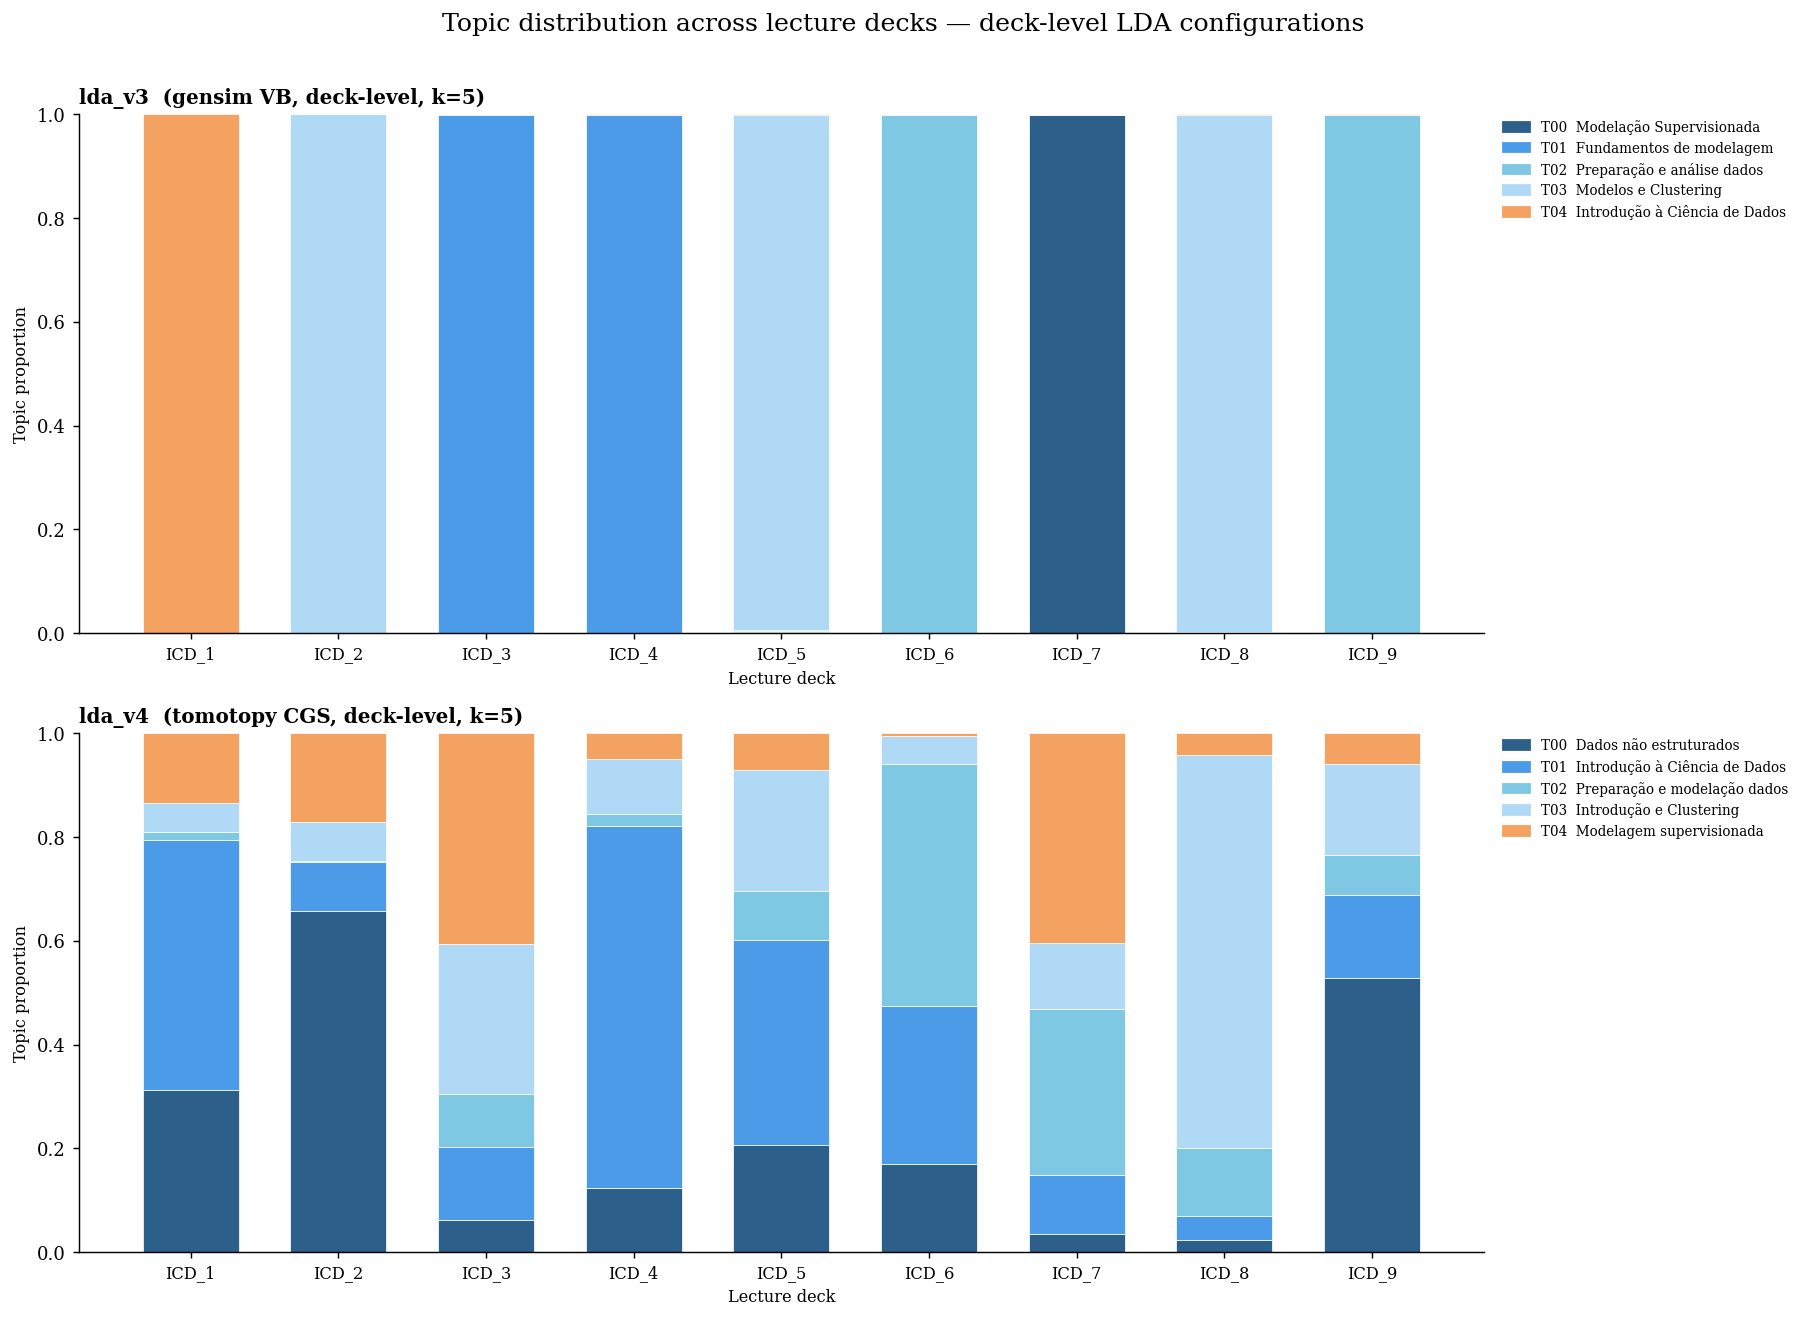

Figure saved to data/output/topic_distribution_deck_models.png


In [6]:

import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

# ── colour palette ─────────────────────────────────────────────────────────────
# 10 distinct colours (one per page-level topic); the deck-level charts use the
# first 5. Chosen to be distinguishable in greyscale print and colourblind-safe.
TOPIC_COLORS_10 = [
    '#2C5F8A', '#4C9BE8', '#7EC8E3', '#B0D9F5',
    '#F4A261', '#E76F51', '#8B5A3C', '#C9A87C',
    '#6A9F6A', '#A8D5A2',
]

# ── helper: extract (n_docs × k) theta matrix ─────────────────────────────────
def _theta_gensim(model, bow_corpus, k):
    theta = np.zeros((len(bow_corpus), k), dtype=float)
    for i, bow in enumerate(bow_corpus):
        for tid, p in model.get_document_topics(bow, minimum_probability=0.0):
            if tid < k:
                theta[i, tid] = p
    row_sums = theta.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return theta / row_sums

def _theta_tomotopy(model):
    theta = np.vstack([np.array(d.get_topic_dist()) for d in model.docs])
    row_sums = theta.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return theta / row_sums

# ── collect theta and labels for each model ────────────────────────────────────
configs = [
    {
        'label'      : 'lda_v3  (gensim VB, deck-level, k=5)',
        'granularity': 'deck',
        'k'          : 5,
        'theta'      : _theta_gensim(m_v3, bow3, 5),
        'topic_labels': generate_topic_labels_llm(m_v3, 5),
        'docs_df'    : deck_docs,
    },
    {
        'label'      : 'lda_v4  (tomotopy CGS, deck-level, k=5)',
        'granularity': 'deck',
        'k'          : 5,
        'theta'      : _theta_tomotopy(m_v4),
        'topic_labels': generate_topic_labels_llm(m_v4, 5),
        'docs_df'    : deck_docs,
    },
]

# ── short deck label (strip "_cleaned_vN.csv" suffix) ─────────────────────────
def _deck_label(source_file):
    name = source_file.replace('_cleaned_v', '_v').split('_v')[0]
    return name.upper()

# ── plot ───────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('Topic distribution across lecture decks — deck-level LDA configurations',
             fontsize=14, y=1.01)

for ax, cfg in zip(axes, configs):
    theta = cfg['theta']          # (n_docs, k)
    k     = cfg['k']
    colors = TOPIC_COLORS_10[:k]
    labels = cfg['topic_labels']
    docs_df = cfg['docs_df'].reset_index(drop=True)

    n_docs  = theta.shape[0]
    x       = np.arange(n_docs)
    width   = 0.65
    deck_col = 'source_file' if 'source_file' in docs_df.columns else docs_df.columns[0]
    xtick_labels = [_deck_label(sf) for sf in docs_df[deck_col]]

    bottom = np.zeros(n_docs)
    for t in range(k):
        ax.bar(x, theta[:, t], width, bottom=bottom,
               color=colors[t], label=f'T{t:02d} {labels[t]}',
               edgecolor='white', linewidth=0.4)
        bottom += theta[:, t]

    ax.set_xticks(x)
    ax.set_xticklabels(xtick_labels, fontsize=9)
    ax.set_xlabel('Lecture deck', fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Topic proportion', fontsize=9)
    ax.set_title(cfg['label'], fontsize=11, fontweight='bold', loc='left')

    handles = [
        mpatches.Patch(color=colors[t], label=f'T{t:02d}  {labels[t]}')
        for t in range(k)
    ]
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1.0),
              fontsize=7.5, frameon=False, borderaxespad=0)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, 'topic_distribution_deck_models.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved to data/output/topic_distribution_deck_models.png')


## 6. Deck-aggregated topic presence — OWN_BEST page-level models

For each lecture deck (9 total), the per-page theta values are averaged across all pages within that deck, yielding a single distribution vector per deck. The stacked bars show how each topic's mean weight varies across decks.

Two configurations are compared side-by-side:
- **Graphic A** — gensim VB, K=4 (OWN_BEST from `lda_v1` grid search)
- **Graphic B** — tomotopy CGS, K=11 (OWN_BEST from `lda_v2` grid search; primary baseline)

In [7]:

# ── Train OWN_BEST page-level models ──────────────────────────────────────────
# lda_v1 OWN_BEST: gensim VB, page-level, k=4
d1b, bow1b = _gensim_bow(page_texts)
m_v1_best = LdaModel(
    corpus=bow1b, id2word=d1b, num_topics=4,
    passes=20, iterations=400, alpha=0.1, eta=0.01,
    random_state=RANDOM_SEED,
)

# lda_v2 OWN_BEST: tomotopy CGS, page-level, k=11
m_v2_best = tp.LDAModel(k=11, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=RANDOM_SEED)
for t in page_texts:
    m_v2_best.add_doc(t)
m_v2_best.train(0)
m_v2_best.train(1000, workers=1)

print('OWN_BEST page-level models trained (k=4 gensim, k=11 tomotopy).')


OWN_BEST page-level models trained (k=4 gensim, k=11 tomotopy).


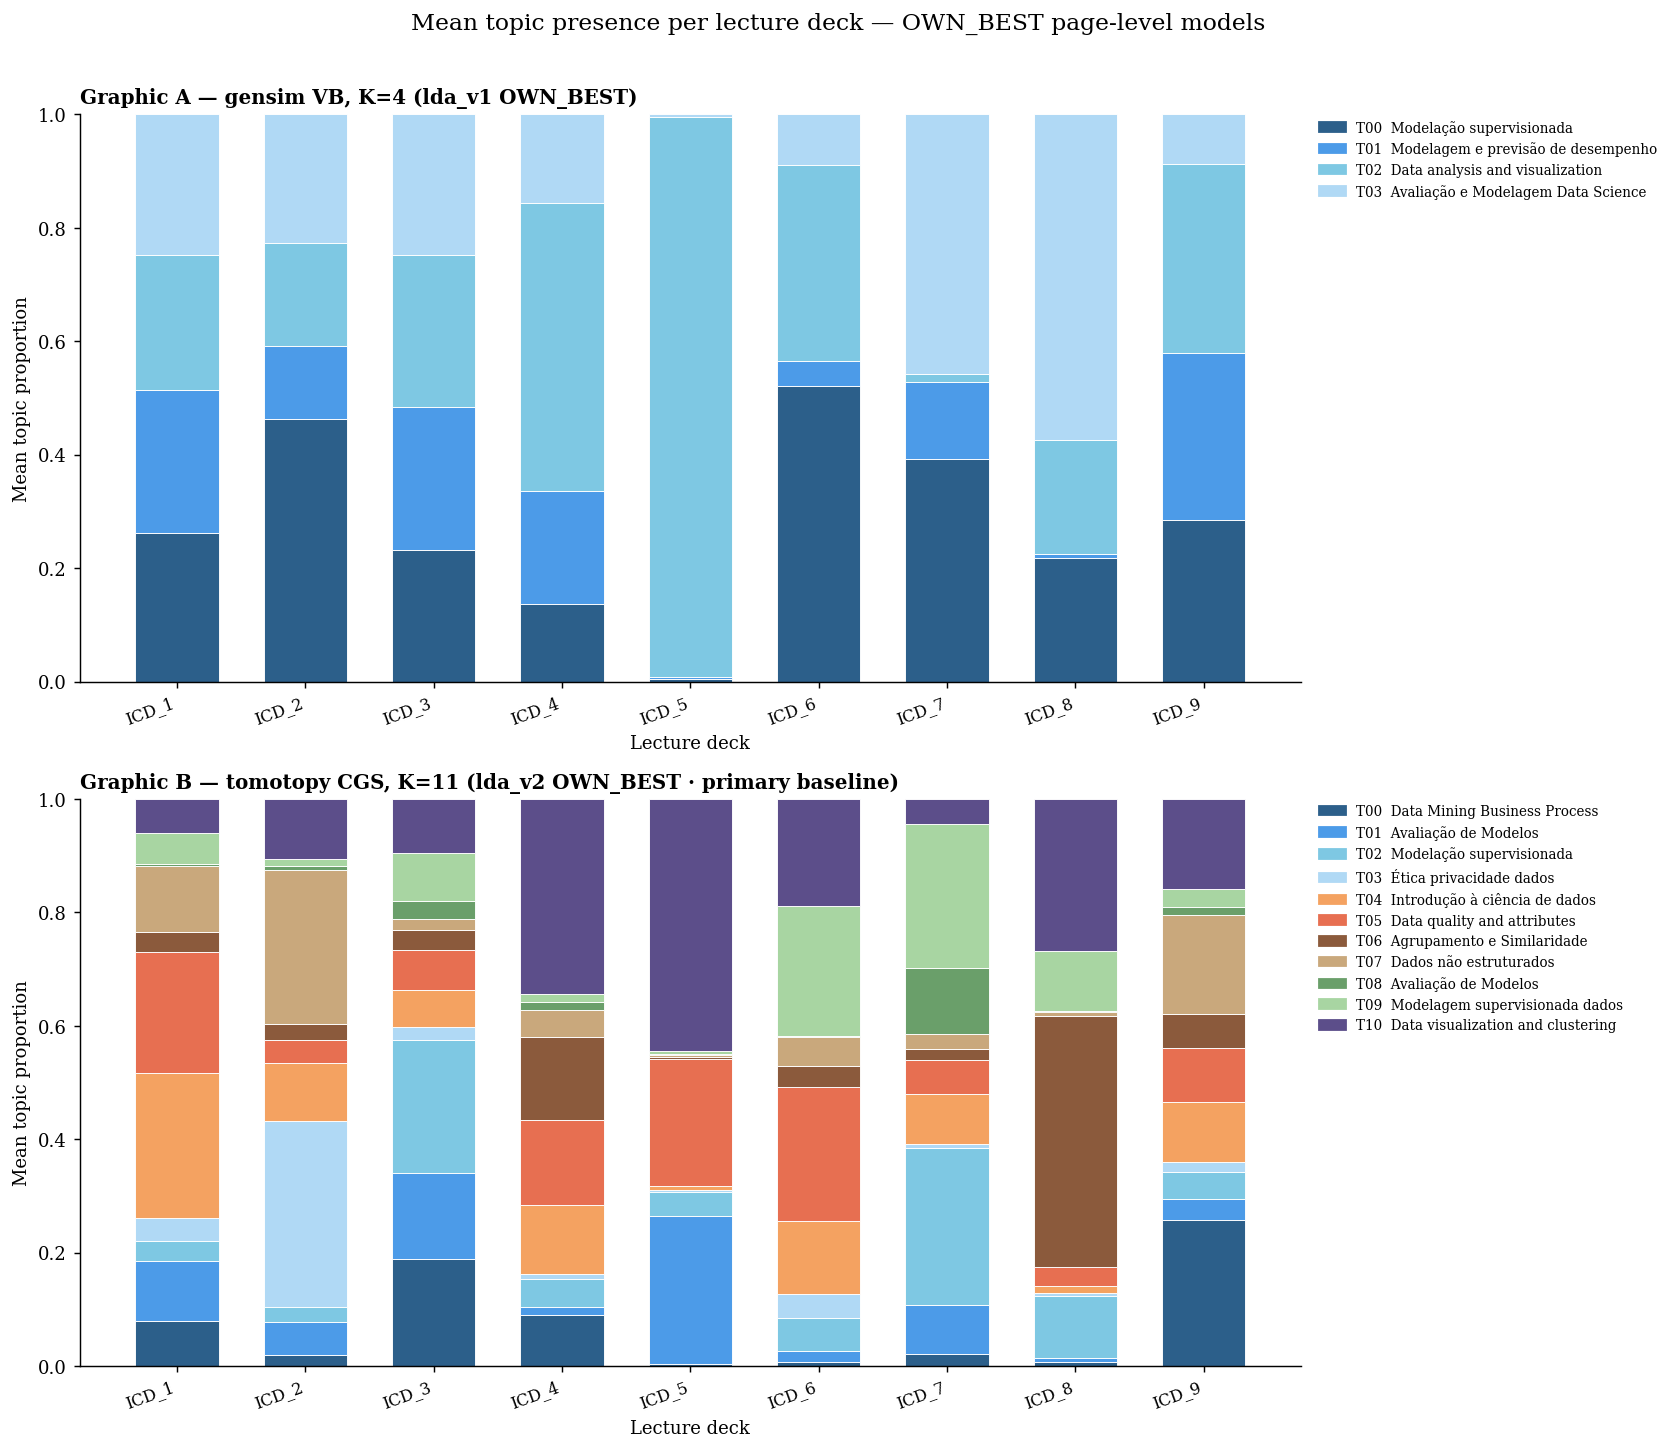

Figure saved to data/output/topic_deck_presence_ownbest.png


In [8]:

import matplotlib.patches as mpatches

# ── 11-color palette (10 existing + 1 extra for k=11) ─────────────────────────
TOPIC_COLORS_11 = TOPIC_COLORS_10 + ['#5C4E8A']

# ── Aggregate page-level theta to deck means ───────────────────────────────────
def _deck_mean_theta(theta, page_docs_df):
    """Average per-page theta across all pages within each deck.
    Returns (deck_labels, deck_theta) where deck_theta is (n_decks, k)."""
    df = page_docs_df.reset_index(drop=True).copy()
    df['_idx'] = df.index
    deck_order = list(dict.fromkeys(df['source_file']))   # preserve order
    deck_labels = [_deck_label(sf) for sf in deck_order]
    deck_theta = np.vstack([
        theta[df[df['source_file'] == sf]['_idx'].values].mean(axis=0)
        for sf in deck_order
    ])
    return deck_labels, deck_theta

page_docs_filtered = page_docs.copy()   # already min_tokens-filtered

deck_labels_v1, deck_theta_v1 = _deck_mean_theta(
    _theta_gensim(m_v1_best, bow1b, 4), page_docs_filtered
)
deck_labels_v2, deck_theta_v2 = _deck_mean_theta(
    _theta_tomotopy(m_v2_best), page_docs_filtered
)

# ── topic labels (top-3 words each) ───────────────────────────────────────────
labels_v1 = generate_topic_labels_llm(m_v1_best, 4)
labels_v2 = generate_topic_labels_llm(m_v2_best, 11)

# ── plot ───────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(13, 11), sharex=False)
fig.suptitle(
    'Mean topic presence per lecture deck — OWN_BEST page-level models',
    fontsize=13, y=1.01
)

_cfgs = [
    dict(ax=axes[0], theta=deck_theta_v1, labels=deck_labels_v1, k=4,
         colors=TOPIC_COLORS_11[:4],  topic_labels=labels_v1,
         title='Graphic A — gensim VB, K=4 (lda_v1 OWN_BEST)'),
    dict(ax=axes[1], theta=deck_theta_v2, labels=deck_labels_v2, k=11,
         colors=TOPIC_COLORS_11[:11], topic_labels=labels_v2,
         title='Graphic B — tomotopy CGS, K=11 (lda_v2 OWN_BEST · primary baseline)'),
]

for cfg in _cfgs:
    ax       = cfg['ax']
    theta    = cfg['theta']          # (9, k)
    k        = cfg['k']
    colors   = cfg['colors']
    x        = np.arange(len(cfg['labels']))
    width    = 0.65

    bottom = np.zeros(len(cfg['labels']))
    for t in range(k):
        ax.bar(x, theta[:, t], width, bottom=bottom,
               color=colors[t], edgecolor='white', linewidth=0.5,
               label=f'T{t:02d}  {cfg["topic_labels"][t]}')
        bottom += theta[:, t]

    ax.set_xticks(x)
    ax.set_xticklabels(cfg['labels'], rotation=20, ha='right', fontsize=9)
    ax.set_xlabel('Lecture deck', fontsize=10)
    ax.set_ylabel('Mean topic proportion', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_title(cfg['title'], fontsize=11, fontweight='bold', loc='left')

    handles = [
        mpatches.Patch(color=colors[t], label=f'T{t:02d}  {cfg["topic_labels"][t]}')
        for t in range(k)
    ]
    ax.legend(handles=handles, loc='upper left',
              bbox_to_anchor=(1.01, 1.0), fontsize=7.5,
              frameon=False, borderaxespad=0)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_ROOT, 'topic_deck_presence_ownbest.png'),
    dpi=150, bbox_inches='tight'
)
plt.show()
print('Figure saved to data/output/topic_deck_presence_ownbest.png')


## 7. Cross-library C_v on a common estimator (Scope A)

`C_v` is estimator-dependent: the gensim (`CoherenceModel`) and tomotopy (`Coherence`) implementations return different scores for identical topics. The native per-library numbers above are therefore **not** directly comparable across libraries. To compare VB vs CGS fairly, this section recomputes `C_v` for every page- and deck-level OWN_BEST/INITIAL model under a **single** estimator (gensim `CoherenceModel`) on a shared reference corpus per granularity. The hLDA-vs-`lda_v2` comparison is unaffected and stays on the tomotopy estimator (both tomotopy).

In [9]:
# Scope A — common-estimator (gensim CoherenceModel) cross-library C_v.
# Self-contained: rebuilds the same splits and trains each model at the reported K.
from sklearn.model_selection import train_test_split
import gensim.corpora as _corpora
from gensim.models import LdaModel as _LdaModel, CoherenceModel as _CoherenceModel
import tomotopy as _tp

_SEED = 42
_page = build_slide_page_docs(corpus_raw); _page = _page[_page['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)
_deck = build_slide_deck_docs(corpus_raw)
_ptr, _ = train_test_split(_page, test_size=0.10, random_state=_SEED); _ptrain = _ptr['tokens'].tolist()
_dtr, _ = train_test_split(_deck, test_size=1,   random_state=_SEED); _dtrain = _dtr['tokens'].tolist()
_pdict = _corpora.Dictionary(_ptrain)   # shared page reference
_ddict = _corpora.Dictionary(_dtrain)   # shared deck reference

def _common_cv(topics_words, dic, texts):
    dt = set(dic.token2id)
    tw = [[w for w in ws if w in dt] for ws in topics_words]
    tw = [ws for ws in tw if len(ws) >= 2]
    return _CoherenceModel(topics=tw, texts=texts, dictionary=dic, coherence='c_v', processes=1).get_coherence()

def _gensim_topics(texts, k, no_above, passes, iters):
    d = _corpora.Dictionary(texts); d.filter_extremes(no_below=2, no_above=no_above); d.compactify()
    m = _LdaModel(corpus=[d.doc2bow(t) for t in texts], id2word=d, num_topics=k,
                  passes=passes, iterations=iters, alpha=0.1, eta=0.01, random_state=_SEED)
    return [[w for w, _ in m.show_topic(i, topn=10)] for i in range(k)]

def _tomo_topics(texts, k, iters):
    m = _tp.LDAModel(k=k, alpha=0.1, eta=0.01, min_df=2, rm_top=0, seed=_SEED)
    for t in texts: m.add_doc(t)
    m.train(0); m.train(iters, workers=1)
    return [[w for w, _ in m.get_topic_words(i, top_n=10)] for i in range(k)]

_rows = [
    ('lda_v1 VB page  k=10', _common_cv(_gensim_topics(_ptrain, 10, 0.8, 20, 400), _pdict, _ptrain)),
    ('lda_v1 VB page  k=4 ', _common_cv(_gensim_topics(_ptrain,  4, 0.8, 20, 400), _pdict, _ptrain)),
    ('lda_v2 CGS page k=10', _common_cv(_tomo_topics(_ptrain, 10, 1000), _pdict, _ptrain)),
    ('lda_v2 CGS page k=11', _common_cv(_tomo_topics(_ptrain, 11, 1000), _pdict, _ptrain)),
    ('lda_v3 VB deck  k=3 ', _common_cv(_gensim_topics(_dtrain, 3, 0.9, 30, 500), _ddict, _dtrain)),
    ('lda_v4 CGS deck k=3 ', _common_cv(_tomo_topics(_dtrain, 3, 2000), _ddict, _dtrain)),
]
print('Common-estimator (gensim CoherenceModel) C_v — fair cross-library comparison:')
for name, cv in _rows:
    print(f'  {name}:  C_v = {cv:.4f}')
print('\nPage-level: CGS (k=11 ~0.52, k=10 ~0.47) > VB (k=10 ~0.40, k=4 ~0.34) under one estimator.')

Dropping 6 empty pages after tokenisation.


Common-estimator (gensim CoherenceModel) C_v — fair cross-library comparison:
  lda_v1 VB page  k=10:  C_v = 0.3951
  lda_v1 VB page  k=4 :  C_v = 0.3442
  lda_v2 CGS page k=10:  C_v = 0.4720
  lda_v2 CGS page k=11:  C_v = 0.5191
  lda_v3 VB deck  k=3 :  C_v = 0.6041
  lda_v4 CGS deck k=3 :  C_v = 0.5717

Page-level: CGS (k=11 ~0.52, k=10 ~0.47) > VB (k=10 ~0.40, k=4 ~0.34) under one estimator.
